# 04 · Visualizaciones (fase *Share*)

> **PRUEBA PRELIMINAR (bitácora D-09, D-11, D-13 a D-16).** Se usa la ventana **2024-11 a 2026-10, 24 meses (D-06)**. Las cifras son resultados de la prueba preliminar y deben revisarse antes de copiarse a documentos finales.

**¿Qué hace este notebook?** Convierte las tablas del análisis (`datos/gold/`) en cinco gráficas pensadas para el documento y el video. No calcula nada nuevo: solo lee lo que ya se calculó y se validó en el notebook 03.

**¿Por qué?** La fase *Share* consiste en contar lo encontrado de forma clara. Cada gráfica lleva como título la idea que muestra, y debajo una lectura en palabras simples. Las imágenes se guardan en `figuras/`.

**Cómo leer los colores:** rojo = una estación **se llena** o se satura (llegan más bicis de las que salen); azul = **se vacía** (salen más bicis de las que llegan). Los mapas se dibujan por coordenadas, con el **contorno de la Ciudad de México** de fondo (capa oficial del SIEG de la CDMX, guardada en `datos/mapa/`) y **sin calles**, para que todo se pueda reproducir sin conexión a internet.

## 0. Preparación

Se cargan las librerías y las tablas resumidas. Los periodos y las estaciones vienen de `config/pipeline.toml`, no están escritos aquí.

In [1]:
import sys
from pathlib import Path

# Localiza la raíz del repositorio (la carpeta que contiene config/pipeline.toml) para poder importar el pipeline.
raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "pipeline.toml").exists())
sys.path.insert(0, str(raiz))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Patch, Rectangle

from pipeline import config

cfg = config.cargar()
a = cfg["analisis"]
periodos = [x["nombre"] for x in cfg["periodos"]]
anterior, reciente = periodos[0], periodos[-1]

# Colores: rojo = la estación se llena o satura (llegan más bicis de las que salen), azul = se vacía. Gris y gris oscuro para lo neutro.
AZUL, ROJO, GRIS, OSCURO = "#2166ac", "#b2182b", "#9a9a9a", "#444444"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
config.FIGURAS.mkdir(exist_ok=True)


def guardar(fig, nombre):
    """Guarda la figura en figuras/ (para el documento y el video) y la muestra aquí."""
    fig.tight_layout()
    fig.savefig(config.FIGURAS / nombre, dpi=150)
    plt.show()


def corto(nombre, largo=36):
    """Quita el prefijo 'CE-123' del nombre de la estación y lo acorta (con puntos suspensivos) para que quepa en las gráficas."""
    partes = str(nombre).split(" ", 1)
    texto = partes[1].strip() if len(partes) > 1 else str(nombre)
    return texto if len(texto) <= largo else texto[:largo - 1].rstrip() + "…"


print("Periodo que se muestra:", reciente, "| periodo de comparación:", anterior)

Periodo que se muestra: 2025-11 a 2026-10 | periodo de comparación: 2024-11 a 2025-10


In [2]:
est = pd.read_parquet(config.GOLD / "estaciones.parquet")
pers = pd.read_parquet(config.GOLD / "persistencia_estacion.parquet")
ph = pd.read_parquet(config.GOLD / "perfil_horario_estacion.parquet")
od = pd.read_parquet(config.GOLD / "od_corredor.parquet")
cor = pd.read_parquet(config.GOLD / "corredor_buenavista_reforma.parquet")
prior = pd.read_parquet(config.GOLD / "estaciones_prioritarias.parquet")
kpi = pd.read_parquet(config.GOLD / "kpi_prioritarias.parquet")
nombres = est.set_index("codigo")["nombre"]
buenavista = a["origenes_buenavista"]
foco = a["estaciones_reforma"][0]
print("Tablas leídas de datos/gold:", len(est), "estaciones en el catálogo,", len(pers), "filas de persistencia.")

Tablas leídas de datos/gold: 677 estaciones en el catálogo, 1362 filas de persistencia.


## 1. Mapa: dónde se vacían y dónde se llenan las estaciones

Cada punto es una estación. El **color** indica su saldo medio por la mañana (llegadas menos salidas entre 7:00 y 10:59 en días laborables) y el **tamaño**, su capacidad. El color se satura en ±60 bicis, así que las estaciones con saldos mayores (como 271-272) aparecen con el color más intenso. El primer mapa muestra la ciudad completa: el servicio cubre una zona central y no todo el territorio. El segundo se acerca a esa zona, y el tercero, a la zona del caso; los círculos negros marcan las 4 estaciones de Buenavista del análisis y las 15 prioritarias que caen en esa zona.

Estaciones en el mapa: 677 (las 6 sin catálogo no tienen coordenadas).


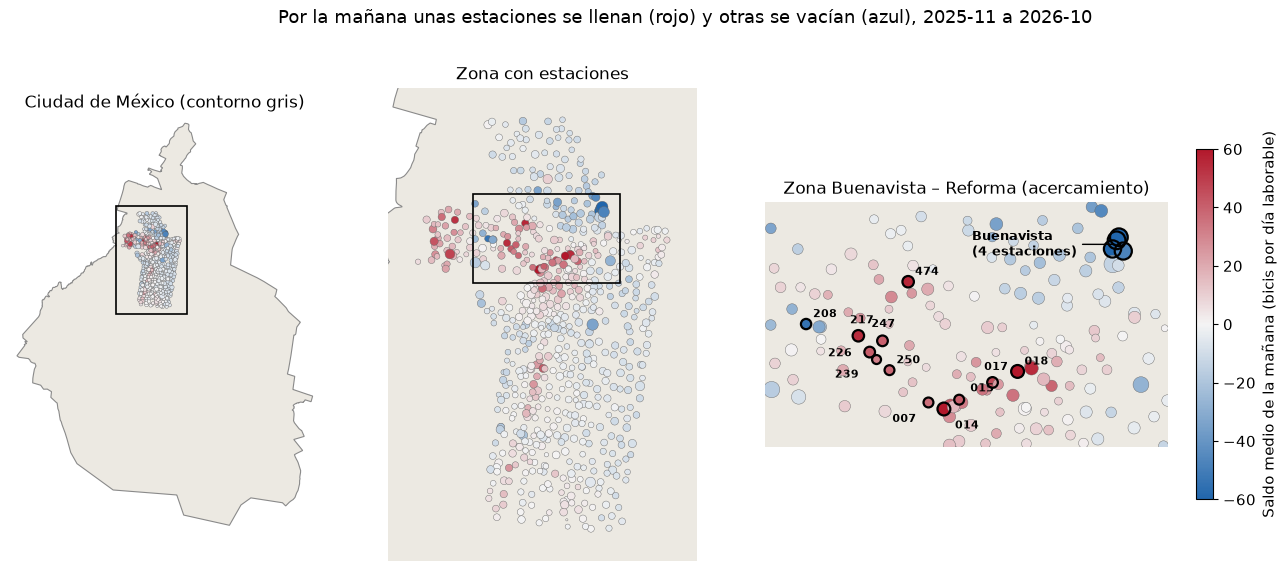

In [3]:
mapa = pers[pers["periodo"] == reciente].merge(est[["codigo", "lat", "lon", "en_reforma"]], left_on="est", right_on="codigo")
print(f"Estaciones en el mapa: {len(mapa)} (las {len(pers[pers['periodo'] == reciente]) - len(mapa)} sin catálogo no tienen coordenadas).")

cmap = LinearSegmentedColormap.from_list("vacia_llena", [AZUL, "#f4f4f4", ROJO])
norm = TwoSlopeNorm(vmin=-60, vcenter=0, vmax=60)
marco = mapa[mapa["est"].isin(buenavista) | mapa["en_reforma"]]
x0, x1 = marco["lon"].min() - 0.004, marco["lon"].max() + 0.004
y0, y1 = marco["lat"].min() - 0.004, marco["lat"].max() + 0.004
rel = 1 / np.cos(np.radians(19.43))   # corrige la deformación de los grados de longitud

# Contorno de la Ciudad de México (capa oficial del SIEG, guardada en datos/mapa/): una lista de polígonos de pares (longitud, latitud).
contorno = json.loads((config.MAPA / "cdmx_contorno.geojson").read_text(encoding="utf8"))["features"][0]["geometry"]
poligonos = contorno["coordinates"] if contorno["type"] == "MultiPolygon" else [contorno["coordinates"]]
lons = [p[0] for pol in poligonos for p in pol[0]]
lats = [p[1] for pol in poligonos for p in pol[0]]

# Zona de servicio: el rectángulo que contiene todas las estaciones del catálogo (con un pequeño margen).
sx0, sx1 = mapa["lon"].min() - 0.01, mapa["lon"].max() + 0.01
sy0, sy1 = mapa["lat"].min() - 0.01, mapa["lat"].max() + 0.01

fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for ax, (xa, xb, ya, yb), datos, escala in (
        (ax0, (min(lons) - 0.01, max(lons) + 0.01, min(lats) - 0.01, max(lats) + 0.01), mapa, 0.25),
        (ax1, (sx0, sx1, sy0, sy1), mapa, 0.9),
        (ax2, (x0, x1, y0, y1), mapa[mapa["lon"].between(x0, x1) & mapa["lat"].between(y0, y1)], 2.2)):
    for pol in poligonos:   # el primer anillo de cada polígono es su borde exterior
        ax.fill([p[0] for p in pol[0]], [p[1] for p in pol[0]], facecolor="#ece9e2", edgecolor="#8a8a8a", linewidth=0.8, zorder=0)
    puntos = ax.scatter(datos["lon"], datos["lat"], c=datos["saldo_medio"], cmap=cmap, norm=norm,
                        s=escala * datos["capacidad"].fillna(20), edgecolor="#666", linewidth=0.3, zorder=2)
    ax.set_xlim(xa, xb)
    ax.set_ylim(ya, yb)
    ax.set_aspect(rel)
    ax.set_xticks([]); ax.set_yticks([])
    for lado in ax.spines.values():
        lado.set_visible(False)
ax0.add_patch(Rectangle((sx0, sy0), sx1 - sx0, sy1 - sy0, fill=False, edgecolor="black", linewidth=1.2, zorder=3))
ax1.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="black", linewidth=1.2, zorder=3))
ax0.set_title("Ciudad de México (contorno gris)", fontsize=12)
ax1.set_title("Zona con estaciones", fontsize=12)
ax2.set_title("Zona Buenavista – Reforma (acercamiento)", fontsize=12)
dentro = mapa[mapa["est"].isin(buenavista) | mapa["est"].isin(prior["est"])]
# Desplazamientos (en puntos) de algunas etiquetas para que no se encimen; las 4 de Buenavista llevan una sola etiqueta de grupo.
desplazar = {"014": (8, -14), "007": (-26, -14), "015": (8, 6), "017": (-6, 9), "247": (-8, 10), "226": (-30, -3), "239": (-30, -13), "217": (-6, 9)}
for r in dentro.itertuples():
    if x0 <= r.lon <= x1 and y0 <= r.lat <= y1:
        ax2.scatter([r.lon], [r.lat], s=2.2 * (r.capacidad if r.capacidad == r.capacidad else 20), facecolor="none",
                    edgecolor="black", linewidth=1.6, zorder=4)
        if r.est not in buenavista:
            ax2.annotate(r.est, (r.lon, r.lat), xytext=desplazar.get(r.est, (5, 5)), textcoords="offset points", fontsize=8, fontweight="bold")
centro = mapa[mapa["est"].isin(buenavista)][["lon", "lat"]].mean()
ax2.annotate("Buenavista\n(4 estaciones)", (centro["lon"], centro["lat"]), xytext=(-105, -8), textcoords="offset points",
             fontsize=9, fontweight="bold", arrowprops=dict(arrowstyle="-", color="black"))
barra = fig.colorbar(puntos, ax=[ax0, ax1, ax2], shrink=0.7, pad=0.02)
barra.set_label("Saldo medio de la mañana (bicis por día laborable)")
fig.suptitle(f"Por la mañana unas estaciones se llenan (rojo) y otras se vacían (azul), {reciente}", fontsize=13)
fig.savefig(config.FIGURAS / "04_mapa_saldo.png", dpi=150, bbox_inches="tight")
plt.show()

**Lectura:** las estaciones que se llenan (rojo) y las que se vacían (azul) tienden a agruparse por zonas. En el acercamiento se ve a Buenavista vaciándose y a las estaciones de Reforma llenándose. También se ven estaciones rojas lejos de esa zona, lo que confirma que **el desbalance no se limita a ese corredor**.

## 2. Perfil horario: a qué hora ocurre

Se cuentan las bicis que salen (azul: la estación se vacía) y las que llegan (rojo: la estación se llena) en cada hora de un día laborable típico. La banda gris es la franja que se analizó. La línea continua es el periodo más reciente y la punteada, el anterior.

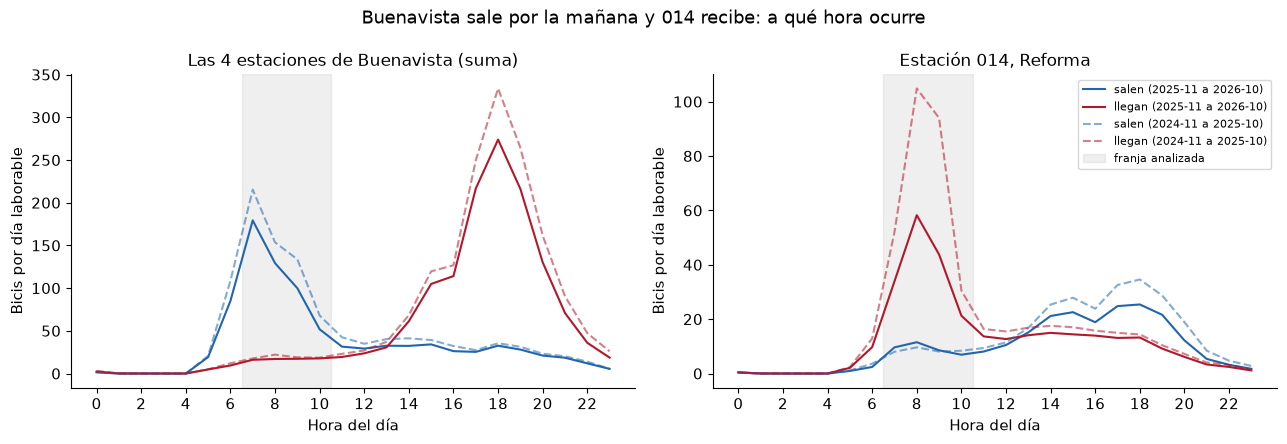

In [4]:
def perfil(codigos, periodo):
    """Salidas y llegadas por día laborable en cada hora, sumadas sobre las estaciones indicadas."""
    t = ph[(ph["periodo"] == periodo) & ph["est"].isin(codigos)].groupby("hora")[["salidas_por_dia", "llegadas_por_dia"]].sum()
    return t.reindex(range(24), fill_value=0)


fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, codigos, titulo in ((ejes[0], buenavista, "Las 4 estaciones de Buenavista (suma)"),
                            (ejes[1], [foco], f"Estación {foco}, Reforma")):
    for periodo, estilo, alfa in ((reciente, "-", 1.0), (anterior, "--", 0.55)):
        t = perfil(codigos, periodo)
        ax.plot(t.index, t["salidas_por_dia"], estilo, color=AZUL, alpha=alfa, label=f"salen ({periodo})")
        ax.plot(t.index, t["llegadas_por_dia"], estilo, color=ROJO, alpha=alfa, label=f"llegan ({periodo})")
    ax.axvspan(a["hora_inicio"] - 0.5, a["hora_fin"] + 0.5, color=GRIS, alpha=0.15, label="franja analizada")
    ax.set_title(titulo, fontsize=12)
    ax.set_xlabel("Hora del día")
    ax.set_ylabel("Bicis por día laborable")
    ax.set_xticks(range(0, 24, 2))
ejes[1].legend(fontsize=8, loc="upper right")
fig.suptitle("Buenavista sale por la mañana y 014 recibe: a qué hora ocurre", fontsize=13)
guardar(fig, "04_perfil_horario_corredor.png")

**Lectura:** en Buenavista las salidas se concentran en la franja de la mañana, con su máximo hacia las 7:00, y en la estación 014 las llegadas se concentran en esas mismas horas, con su máximo hacia las 8:00. Por la tarde ocurre lo contrario: **a Buenavista llegan muchas bicis, con su máximo hacia las 18:00**, que es el regreso. Entre un periodo y otro el patrón conserva su forma, pero el **volumen baja**, mucho más en 014 que en Buenavista. Estas gráficas muestran *cuándo* pasa, no *por qué*.

## 3. Las 15 estaciones prioritarias

La **presión** mide qué tan grande es el desbalance comparado con el tamaño de la estación: un valor de 2 significa que, en promedio, el saldo de la mañana equivale a dos veces su capacidad. Se muestran las 15 estaciones con más presión cuyo desbalance se repite en al menos 80 % de los días (bitácora D-15).

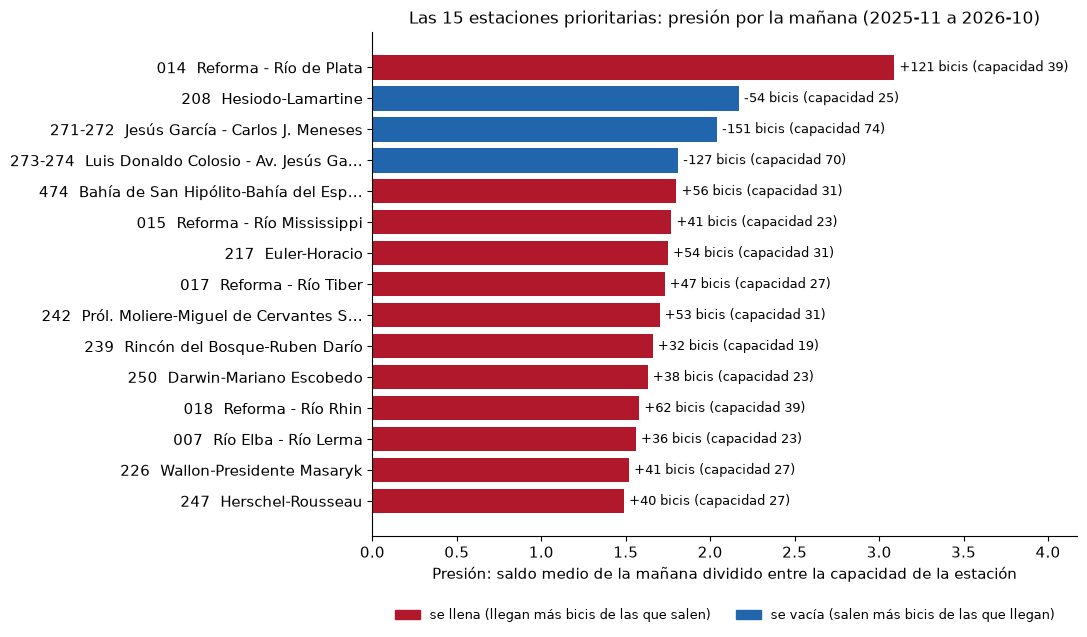

In [5]:
pr = prior.copy()
pr["etiqueta"] = pr["est"] + "  " + pr["nombre"].map(corto)
pr = pr.iloc[::-1]   # la de mayor presión arriba
fig, ax = plt.subplots(figsize=(11, 6.5))
colores = pr["tipo"].map({"se llena": ROJO, "se vacía": AZUL})
ax.barh(pr["etiqueta"], pr["presion"].abs(), color=colores)
for y, (_, r) in enumerate(pr.iterrows()):
    ax.text(abs(r["presion"]) + 0.03, y, f"{r['saldo_medio']:+.0f} bicis (capacidad {int(r['capacidad'])})", va="center", fontsize=9)
ax.set_xlabel("Presión: saldo medio de la mañana dividido entre la capacidad de la estación")
ax.set_xlim(0, pr["presion"].abs().max() * 1.35)
ax.legend(handles=[Patch(color=ROJO, label="se llena (llegan más bicis de las que salen)"),
                   Patch(color=AZUL, label="se vacía (salen más bicis de las que llegan)")], loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=9)
ax.set_title(f"Las 15 estaciones prioritarias: presión por la mañana ({reciente})", fontsize=12)
guardar(fig, "04_ranking_prioritarias.png")

**Lectura:** la mayoría de las estaciones prioritarias son de las que **se llenan**, y solo algunas se vacían. Incluyen estaciones de Reforma, pero también de otras zonas. La capacidad que se usa es la actual del catálogo; se comprobó que casi no cambió desde 2024 (bitácora D-16).

## 4. A dónde van quienes salen de Buenavista

Se cuentan los destinos de los viajes que salen de las 4 estaciones de Buenavista entre 7:00 y 10:59. En gris oscuro, los destinos que son estaciones de Reforma.

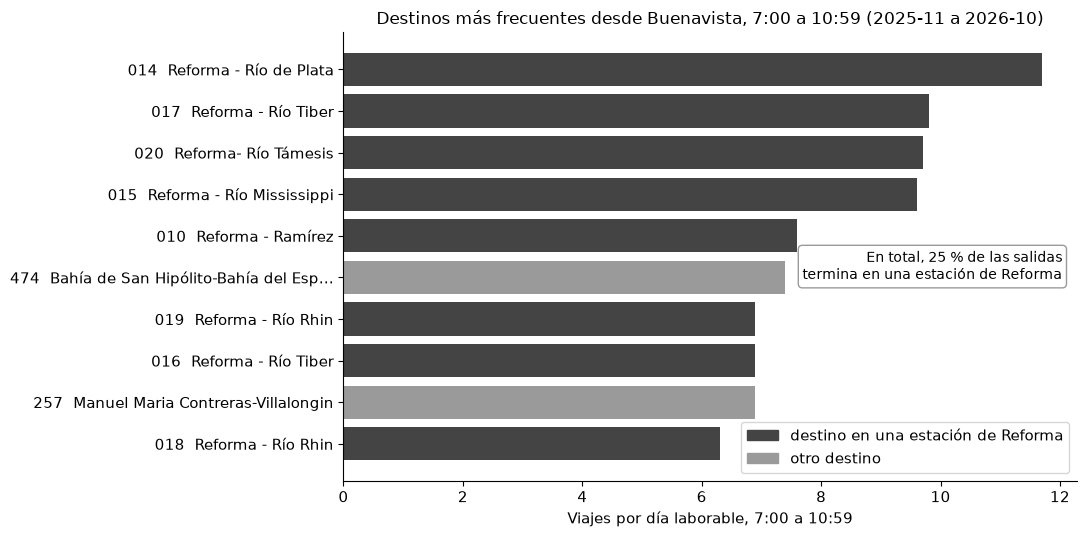

In [6]:
d = od[od["periodo"] == reciente].groupby("destino")["viajes_por_dia"].sum().sort_values(ascending=False)
en_reforma = set(est.loc[est["en_reforma"], "codigo"])
top = d.head(10).iloc[::-1]
etiquetas = [f"{c}  {corto(nombres.get(c, c))}" for c in top.index]
pct = cor[(cor["periodo"] == reciente) & (cor["grupo"] == "núcleo")]["pct_a_reforma"].iloc[0]
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(etiquetas, top.values, color=[OSCURO if c in en_reforma else GRIS for c in top.index])
ax.set_xlabel("Viajes por día laborable, 7:00 a 10:59")
ax.legend(handles=[Patch(color=OSCURO, label="destino en una estación de Reforma"), Patch(color=GRIS, label="otro destino")], loc="lower right")
ax.set_title(f"Destinos más frecuentes desde Buenavista, 7:00 a 10:59 ({reciente})", fontsize=12)
ax.text(0.98, 0.45, f"En total, {pct:.0f} % de las salidas\ntermina en una estación de Reforma", transform=ax.transAxes,
        ha="right", fontsize=10, bbox=dict(boxstyle="round", facecolor="white", edgecolor=GRIS))
guardar(fig, "04_destinos_buenavista.png")

**Lectura:** ocho de los diez destinos más frecuentes son estaciones de Reforma, pero ninguno recibe más de unos 12 viajes por día. En total, solo **una cuarta parte** de las salidas de Buenavista termina en Reforma; el resto se reparte entre muchísimos destinos. Por eso el caso no debe presentarse como un único flujo "de Buenavista a Reforma": hay un movimiento hacia Reforma, pero es una parte del problema (bitácora D-14).

## 5. Línea base: qué tan seguido ocurre

Para cada estación prioritaria se cuenta en qué porcentaje de los días laborables el saldo de la mañana **supera su capacidad**. Esta es la **línea base** del plan de acción: sirve para medir, más adelante, si algo cambió. No es una meta ni un resultado.

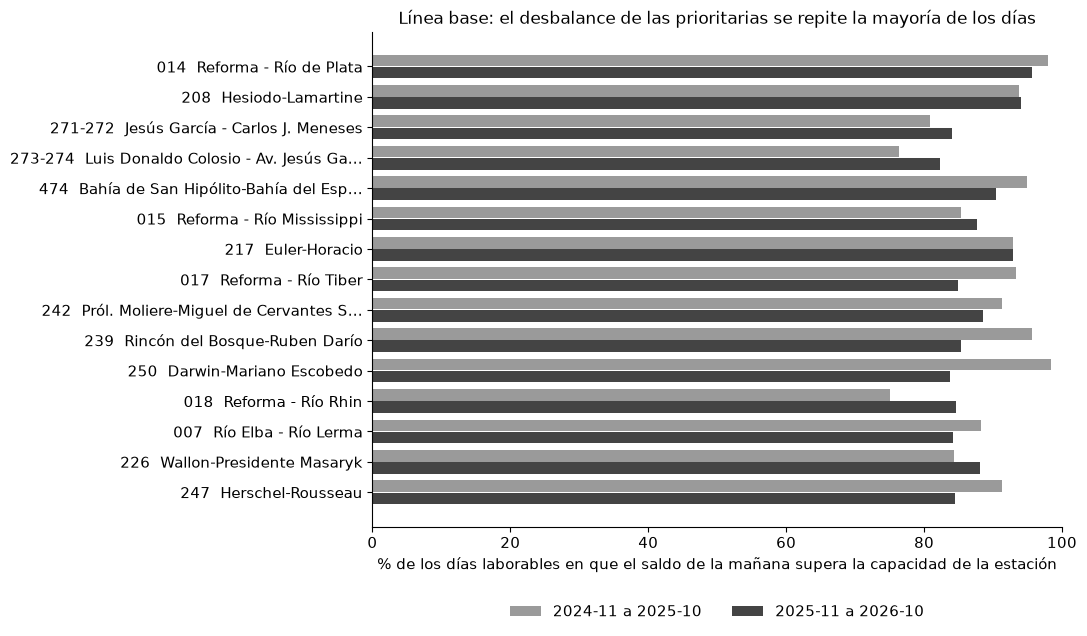

In [7]:
kb = kpi.pivot(index=["posicion", "est", "nombre"], columns="periodo", values="pct_dias_saldo_mayor_capacidad").reset_index().sort_values("posicion", ascending=False)
y = np.arange(len(kb))
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.barh(y + 0.2, kb[anterior], height=0.38, color=GRIS, label=anterior)
ax.barh(y - 0.2, kb[reciente], height=0.38, color=OSCURO, label=reciente)
ax.set_yticks(y)
ax.set_yticklabels([f"{r.est}  {corto(r.nombre)}" for r in kb.itertuples()])
ax.set_xlim(0, 100)
ax.set_xlabel("% de los días laborables en que el saldo de la mañana supera la capacidad de la estación")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False)
ax.set_title("Línea base: el desbalance de las prioritarias se repite la mayoría de los días", fontsize=12)
guardar(fig, "04_linea_base_prioritarias.png")

**Lectura:** en las estaciones prioritarias el desbalance no es ocasional: se repite en la gran mayoría de los días laborables y casi no cambió entre los dos periodos. Un plan de acción tendría que reducir esa frecuencia, y cualquier mejora esperada es una **hipótesis**, no un resultado.

## 6. Cifras clave para el documento y el video

Se calculan aquí desde las tablas para que el texto del documento use los mismos números que las gráficas (y no cifras copiadas a mano):

In [8]:
p = pers[pers["periodo"] == reciente].set_index("est")
bv = cor[(cor["periodo"] == reciente) & (cor["grupo"] == "núcleo")].iloc[0]
cf = pd.read_parquet(config.GOLD / "contraflujo_corredor.parquet")
cf = cf[(cf["periodo"] == reciente) & (cf["grupo"] == "núcleo")].iloc[0]
print(f"Periodo: {reciente}")
print(f"- Estación {foco}: gana {p.loc[foco, 'saldo_medio']:.0f} bicis por mañana laborable; recibe más de lo que sale en {p.loc[foco, 'pct_dias_gana']:.0f} % de los días.")
print(f"- Buenavista (4 estaciones): salen {bv['salidas_por_dia']:.0f} bicis por mañana, y {bv['pct_a_reforma']:.0f} % termina en una estación de Reforma.")
print(f"- Contraflujo Reforma -> Buenavista: {cf['contraflujo_por_dia']:.0f} viajes por día frente a {cf['flujo_principal_por_dia']:.0f} en el sentido principal.")
print(f"- Estaciones prioritarias: {(prior['tipo'] == 'se llena').sum()} se llenan y {(prior['tipo'] == 'se vacía').sum()} se vacían.")
k_rec = kpi[kpi["periodo"] == reciente]["pct_dias_saldo_mayor_capacidad"].mean()
k_ant = kpi[kpi["periodo"] == anterior]["pct_dias_saldo_mayor_capacidad"].mean()
print(f"- En las prioritarias el saldo supera la capacidad en {k_rec:.0f} % de los días ({k_ant:.0f} % en el periodo anterior).")

Periodo: 2025-11 a 2026-10
- Estación 014: gana 121 bicis por mañana laborable; recibe más de lo que sale en 100 % de los días.
- Buenavista (4 estaciones): salen 453 bicis por mañana, y 25 % termina en una estación de Reforma.
- Contraflujo Reforma -> Buenavista: 6 viajes por día frente a 112 en el sentido principal.
- Estaciones prioritarias: 12 se llenan y 3 se vacían.
- En las prioritarias el saldo supera la capacidad en 87 % de los días (89 % en el periodo anterior).


## 7. Qué no muestran estas gráficas

- **No hay inventario:** los viajes muestran movimientos, no cuántas bicis había en cada estación ni cuánta demanda se quedó sin atender.
- **No explican causas.** Se ve *dónde* y *cuándo* se desbalancean las estaciones, no por qué. La caída de la estación 014 entre periodos no se explica con estos datos (bitácora D-14).
- **Correlación no es causalidad:** que las salidas de Buenavista y las llegadas a Reforma coincidan en el horario no demuestra que unas causen las otras.
- **Capacidad actual:** se usa la capacidad del catálogo de 2026-11-20 (bitácora D-16).
- **El grupo de Buenavista** sigue pendiente de confirmarse en el mapa por el equipo (D-13).

**Archivos generados en `figuras/`:** `04_mapa_saldo.png`, `04_perfil_horario_corredor.png`, `04_ranking_prioritarias.png`, `04_destinos_buenavista.png` y `04_linea_base_prioritarias.png`. La serie mensual de la estación 014 está en `03_serie_014.png`.